Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_1             │ ?                      │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d_1          │ ?                      │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/12
313/313 ━━━━━━━━━━━━━━━━━━━━ 62s 182ms/step - accuracy: 0.7688 - auc: 0.8626 - loss: 0.4603 - val_accuracy: 0.8688 - val_auc: 0.9411 - val_loss: 0.3120 - learning_rate: 0.0010
Epoch 2/12
313/313 ━━━━━━━━━━━━━━━━━━━━ 55s 174ms/step - accuracy: 0.9061 - auc: 0.9629 - loss: 0.2441 - val_accuracy: 0.8706 - val_auc: 0.9440 - val_loss: 0.3218 - learning_rate: 0.0010
Epoch 3/12
313/313 ━━━━━━━━━━━━━━━━━━━━ 83s 176ms/step - accuracy: 0.9349 - auc: 0.9785 - loss: 0.1808 - val_accuracy: 0.8612 - val_auc: 0.9422 - val_loss: 0.4006 - learning_rate: 0.0010
Epoch 4/12
313/313 ━━━━━━━━━━━━━━━━━━━━ 85s 185ms/step - accuracy: 0.9596 - auc: 0.9893 - loss: 0.1211 - val_accuracy: 0.8670 - val_auc: 0.9400 - val_loss: 0.4314 - learning_rate: 5.0000e-04
391/391 ━━━━━━━━━━━━━━━━━━━━ 21s 53ms/step - accuracy: 0.8612 - auc: 0.9398 - loss: 0.3168
Test Loss: 0.31678134202957153
Test Accuracy: 0.8611599802970886
Test AUC: 0.9398483633995056


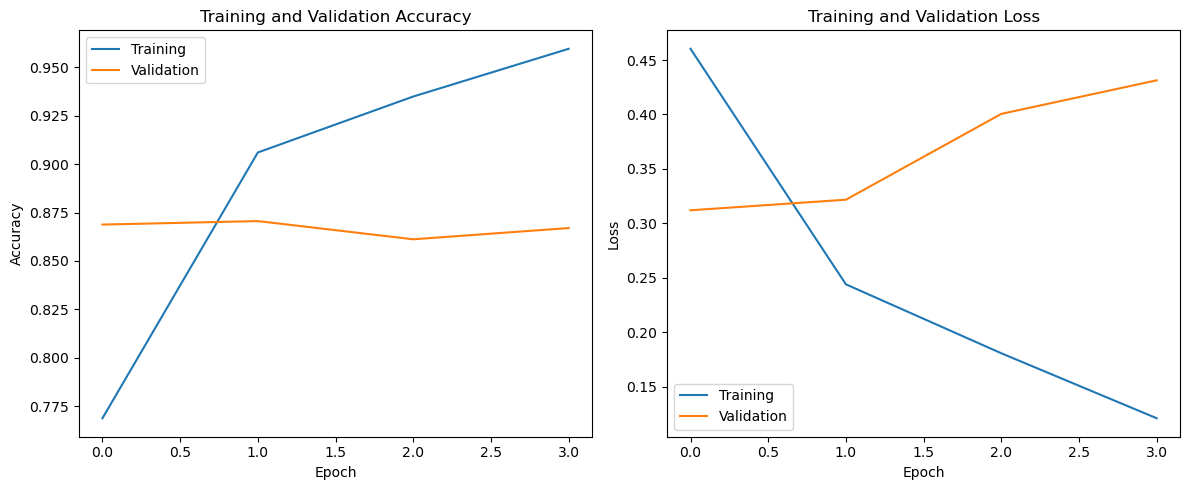

In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding,
    SpatialDropout1D,
    Bidirectional,
    LSTM,
    GlobalMaxPooling1D,
    GlobalAveragePooling1D,
    Dense,
    Dropout
)
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

VOCAB_SIZE = 10000
MAX_LEN = 256
EMBEDDING_DIM = 128
BATCH_SIZE = 64
EPOCHS = 12
SEED = 42

tf.random.set_seed(SEED)
np.random.seed(SEED)

(x_train, y_train), (x_test, y_test) = imdb.load_data(
    num_words=VOCAB_SIZE
)

x_train = pad_sequences(
    x_train,
    maxlen=MAX_LEN,
    padding='post',
    truncating='post'
)

x_test = pad_sequences(
    x_test,
    maxlen=MAX_LEN,
    padding='post',
    truncating='post'
)

validation_size = int(0.2 * len(x_train))

x_val = x_train[:validation_size]
y_val = y_train[:validation_size]

x_train_new = x_train[validation_size:]
y_train_new = y_train[validation_size:]

model = Sequential([
    Embedding(
        input_dim=VOCAB_SIZE,
        output_dim=EMBEDDING_DIM
    ),

    SpatialDropout1D(0.2),

    Bidirectional(
        LSTM(64, return_sequences=True)
    ),

    GlobalMaxPooling1D(),

    Dense(64, activation='relu'),

    Dropout(0.4),

    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.AUC(name='auc')
    ]
)

model.summary()

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

model_checkpoint = ModelCheckpoint(
    'best_imdb_model.keras',
    monitor='val_loss',
    save_best_only=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-6
)

history = model.fit(
    x_train_new,
    y_train_new,
    validation_data=(x_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[
        early_stopping,
        model_checkpoint,
        reduce_lr
    ]
)

test_loss, test_accuracy, test_auc = model.evaluate(
    x_test,
    y_test,
    batch_size=BATCH_SIZE
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test AUC:", test_auc)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Training', 'Validation'])

plt.subplot(1, 2, 2)

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Training', 'Validation'])

plt.tight_layout()
plt.show()